# 📈 Indian Mutual Fund — Top Performers

### Historical Performance Analysis

This notebook analyzes historical NAV data from **CAMS and KFINTECH** and
highlights mutual-fund products that have shown strong historical performance.

### Dataset Selection

The analysis started with approximately **40 million NAV records**.

The data was filtered to retain mutual-fund products that:

- Were **still active in 2025**
- Had **positive historical returns**
- Had usable NAV history from the available CAMS and KFINTECH data

After processing and filtering, the resulting dataset contains **9,076
selected products**.

### Metrics Analyzed

- Annualized Return
- Total Return
- Sortino Ratio
- Maximum Drawdown
- Downside Volatility
- Best Calendar-Year Return
- Worst Calendar-Year Return

In [ ]:
# @title Imports

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [ ]:
# @title
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# @title Load Datasets

df = pd.read_parquet("/content/drive/MyDrive/NAVs/dataset/returns.parquet")
combined_overall = pd.read_parquet("/content/drive/MyDrive/NAVs/dataset/combined_overall.parquet")


cams_metadata = pd.read_parquet(
    "/content/drive/MyDrive/NAVs/dataset/cams_product_metadata.parquet"
)

kfintech_metadata = pd.read_parquet(
    "/content/drive/MyDrive/NAVs/dataset/kfintech_fcode_desc_metadata.parquet"
)


In [ ]:
# @title
def plot_nav(product_id):
    product_id = str(product_id)

    # Determine source and lookup ID
    if "_" in product_id:
        source = "KFINTECH"
        lookup_id = product_id.split("_")[-1]
    else:
        source = "CAMS"
        lookup_id = product_id

    # Overall information
    info = combined_overall[
        (combined_overall["source"] == source) &
        (combined_overall["product_id"].astype(str) == lookup_id)
    ].iloc[0]

    # Load NAV data
    nav = pd.read_parquet(f"/content/drive/MyDrive/NAVs/dataset/{product_id}.parquet")
    nav = nav.sort_values("NAV_DATE")

    # Metadata
    if source == "CAMS":

        metadata = cams_metadata[
            cams_metadata["PRODCODE"] == product_id
        ].iloc[0]

        fund_name = metadata["NAME"]
        isin = metadata["ISIN_NO"]

    else:

        metadata = kfintech_metadata[
            kfintech_metadata["FCODE_DESC_ID"] == int(lookup_id)
        ].iloc[0]

        fund_name = metadata["FUNDDESC"]
        isin = metadata["SCHEMEISIN"]

    # Plot
    plt.figure(figsize=(10, 5))

    plt.plot(
        nav["NAV_DATE"],
        nav["NAV_VALUE"]
    )

    plt.title(
        fund_name,
        fontsize=16,
        pad=12
    )

    plt.text(
        0.5,
        1.01,
        f"Product ID: {product_id} • "
        f"{info['source']} • "
        f"ISIN: {isin} • "
        f"{info['duration_years']:.1f} Years",
        transform=plt.gca().transAxes,
        ha="center",
        fontsize=10
    )

    plt.xlabel("Date")
    plt.ylabel("NAV")

    plt.grid(axis="y", linestyle="--", alpha=0.3)

    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

## Distribution of Products by RTA Over the Years

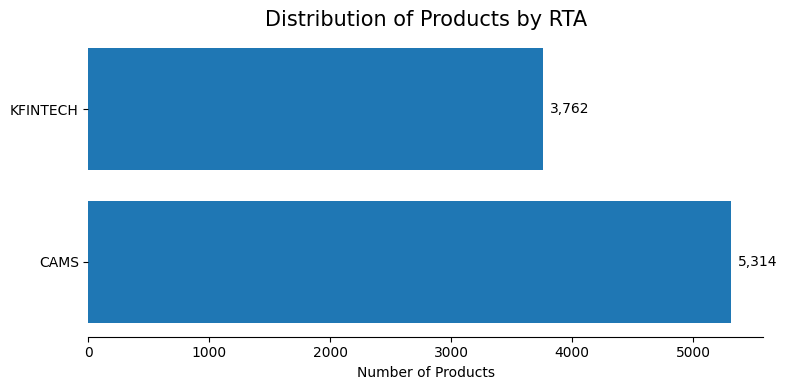

In [ ]:
# @title Distribution of Products by RTA

rta_counts = df["RTA"].value_counts()

plt.figure(figsize=(8, 4))

bars = plt.barh(rta_counts.index, rta_counts.values)

plt.title("Distribution of Products by RTA", fontsize=15)
plt.xlabel("Number of Products")

plt.bar_label(bars, fmt="{:,.0f}", padding=5)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

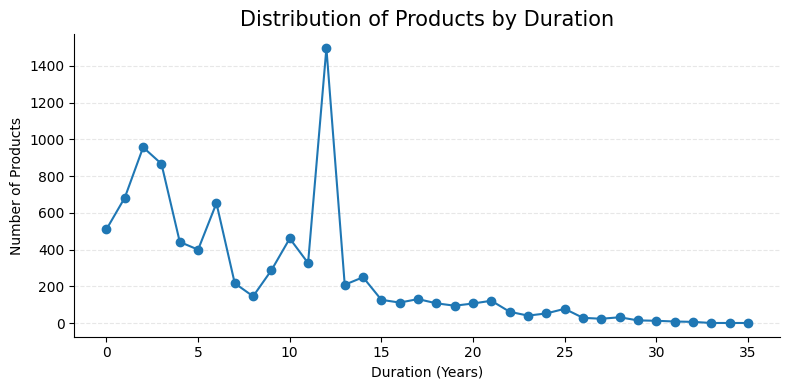

In [ ]:
# @title Distribution of Products by Duration

duration_counts = df["duration_years"].value_counts().sort_index()

plt.figure(figsize=(8, 4))

plt.plot(
    duration_counts.index,
    duration_counts.values,
    marker="o"
)

plt.title("Distribution of Products by Duration", fontsize=15)
plt.xlabel("Duration (Years)")
plt.ylabel("Number of Products")

plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## Performance Analysis

In [ ]:
# @title Overall Performance

overall = df.sort_values(
    "total_return_pct",
    ascending=False
)

result = overall[
    [
        "RTA",
        "product_id",
        "duration_years",
        "total_return_pct",
        "annualized_return_pct",
        "best_year_return_pct",
        "worst_year_return_pct",
        "max_drawdown_pct",
        "downside_volatility",
        "sortino_ratio"
    ]
].rename(columns={
    "duration_years": "Duration (Years)",
    "total_return_pct": "Total Return (%)",
    "annualized_return_pct": "Annualized Return (%)",
    "best_year_return_pct": "Best Year Return (%)",
    "worst_year_return_pct": "Worst Year Return (%)",
    "max_drawdown_pct": "Max Drawdown (%)",
    "downside_volatility": "Downside Volatility",
    "sortino_ratio": "Sortino Ratio"
}).reset_index(drop=True)

result.index = result.index + 1

result

,RTA,product_id,Duration (Years),Total Return (%),Annualized Return (%),Best Year Return (%),Worst Year Return (%),Max Drawdown (%),Downside Volatility,Sortino Ratio
1,KFINTECH,RMFGFGP_13943,29,37547.542000,22.692638,203.445693,-54.599727,-66.749124,16.234932,0.966597
2,CAMS,FTI036,25,16777.603574,22.770050,175.615595,-62.724444,-70.117850,16.502562,0.955612
3,CAMS,B51,26,16737.900000,21.794158,280.056711,-56.799533,-74.143711,18.397326,0.804147
4,CAMS,FTI034,26,14437.063918,21.107818,153.711340,-49.300697,-57.343397,15.743108,0.896127
5,KFINTECH,RMFGSGP_13994,29,13559.725000,18.477513,157.362885,-52.262304,-60.819956,16.418461,0.699061
...,...,...,...,...,...,...,...,...,...,...
9072,KFINTECH,116OVDW_5421,5,0.000190,0.000038,0.040201,-0.036177,-0.131337,0.575736,-12.158288
9073,KFINTECH,178ONID_12364,6,0.000180,0.000030,0.000180,-0.000020,-0.011589,0.006527,-1072.390462
9074,CAMS,FTI865,6,0.000080,0.000013,0.000080,0.000000,-0.058336,0.031123,-224.914589
9075,KFINTECH,117ONRD_5754,5,0.000040,0.000008,0.000070,-0.000020,-0.003050,0.001269,-5517.135204


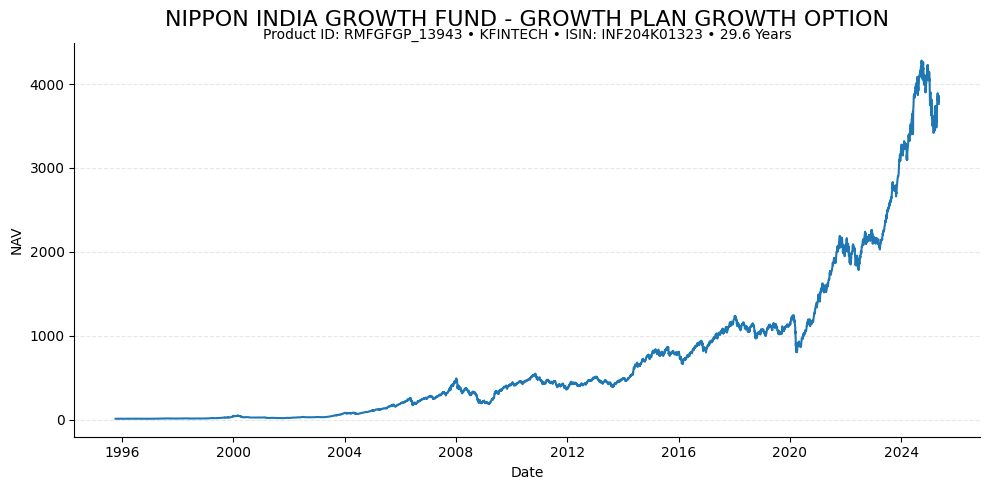

In [ ]:
# @title RMFGFGP_13943 — NAV History

plot_nav("RMFGFGP_13943")

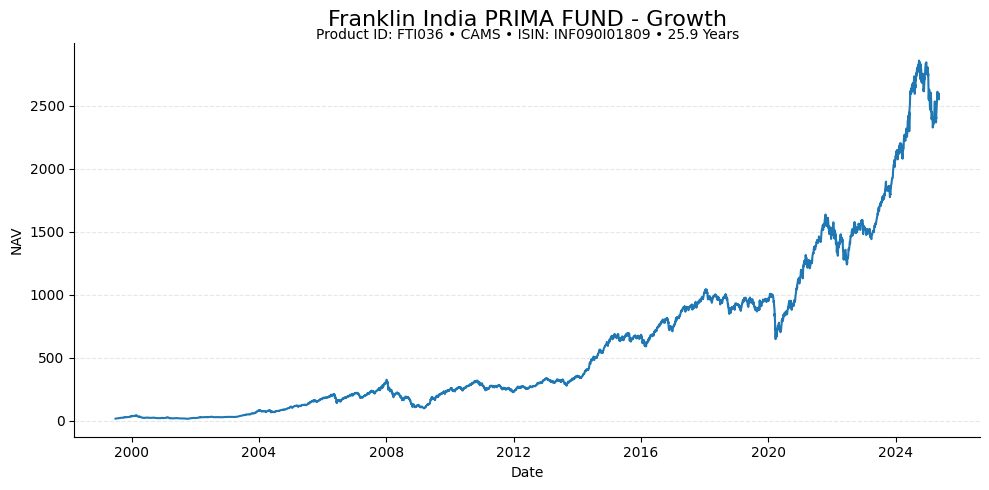

In [ ]:
# @title FTI036 — NAV History

plot_nav("FTI036")

In [ ]:
# @title Top Performing Funds — 2-Year Duration

two_year = df[df["duration_years"] == 2].sort_values(
    "total_return_pct",
    ascending=False
)

result = two_year[
    [
        "RTA",
        "product_id",
        "total_return_pct",
        "annualized_return_pct",
        "best_year_return_pct",
        "worst_year_return_pct",
        "max_drawdown_pct",
        "downside_volatility",
        "sortino_ratio"
    ]
].rename(columns={
    "total_return_pct": "Total Return (%)",
    "annualized_return_pct": "Annualized Return (%)",
    "best_year_return_pct": "Best Year Return (%)",
    "worst_year_return_pct": "Worst Year Return (%)",
    "max_drawdown_pct": "Max Drawdown (%)",
    "downside_volatility": "Downside Volatility",
    "sortino_ratio": "Sortino Ratio"
}).reset_index(drop=True)

result.index = result.index + 1

result

,RTA,product_id,Total Return (%),Annualized Return (%),Best Year Return (%),Worst Year Return (%),Max Drawdown (%),Downside Volatility,Sortino Ratio
1,CAMS,K273,171.648000,64.817475,97.324000,-4.782135,-23.635388,9.801898,5.898600
2,KFINTECH,127SVGR_7718,138.447910,54.417586,58.338906,0.624992,-21.805391,18.603544,2.548847
3,KFINTECH,127S3GD_7699,134.711000,53.202807,57.243605,0.596177,-21.812471,18.549374,2.490801
4,KFINTECH,127S3GP_7700,130.548000,51.838072,56.207439,0.366992,-22.110143,18.550637,2.417064
5,CAMS,P9691,101.500000,41.950696,54.107649,-2.136960,-23.034424,16.579389,2.108081
...,...,...,...,...,...,...,...,...,...
953,CAMS,SH205DP,0.401000,0.200299,0.296000,-0.053830,-0.685272,1.489572,-4.564867
954,CAMS,SH205D,0.401000,0.200299,0.296000,-0.053830,-0.685272,1.488303,-4.568760
955,CAMS,SH205P,0.399000,0.199301,0.272000,-0.048850,-0.856599,1.494059,-4.551828
956,CAMS,SH205,0.399000,0.199301,0.272000,-0.048850,-0.856599,1.494059,-4.551828


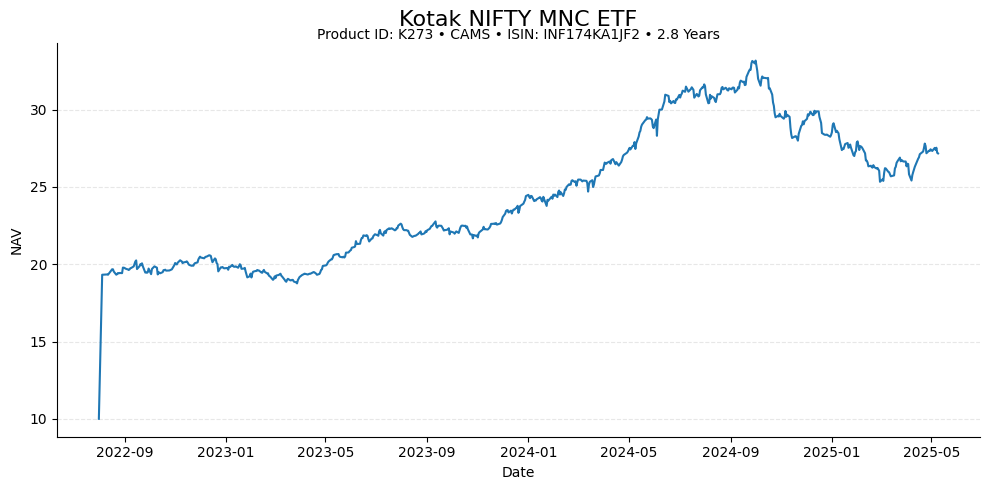

In [ ]:
# @title K273 — NAV History

plot_nav("K273")

In [ ]:
# @title Top Performing Funds — 3-Year Duration

three_year = df[df["duration_years"] == 3].sort_values(
    "total_return_pct",
    ascending=False
)

result = three_year[
    [
        "RTA",
        "product_id",
        "total_return_pct",
        "annualized_return_pct",
        "best_year_return_pct",
        "worst_year_return_pct",
        "max_drawdown_pct",
        "downside_volatility",
        "sortino_ratio"
    ]
].rename(columns={
    "total_return_pct": "Total Return (%)",
    "annualized_return_pct": "Annualized Return (%)",
    "best_year_return_pct": "Best Year Return (%)",
    "worst_year_return_pct": "Worst Year Return (%)",
    "max_drawdown_pct": "Max Drawdown (%)",
    "downside_volatility": "Downside Volatility",
    "sortino_ratio": "Sortino Ratio"
}).reset_index(drop=True)

result.index = result.index + 1

result

,RTA,product_id,Total Return (%),Annualized Return (%),Best Year Return (%),Worst Year Return (%),Max Drawdown (%),Downside Volatility,Sortino Ratio
1,KFINTECH,117NTRG_5749,161.350000,37.744469,73.190000,7.668038,-23.161540,12.987948,2.367154
2,KFINTECH,117TPRG_5802,123.490000,30.743277,52.765000,-17.340742,-22.618552,14.810984,1.603086
3,KFINTECH,RMFNOGP_14592,104.810069,26.994165,47.725029,-2.247435,-28.253623,13.541478,1.476513
4,CAMS,K271,98.097000,25.591226,34.257000,-0.285407,-18.094143,7.597389,2.447055
5,CAMS,LF186G,95.801424,25.104217,25.126305,12.956535,-10.834780,8.860474,2.043256
...,...,...,...,...,...,...,...,...,...
863,KFINTECH,176LFPM_11016,0.347139,0.115579,0.179062,-0.299536,-0.657778,2.021745,-3.405187
864,KFINTECH,176FFZM_10877,0.318527,0.106063,0.242519,-0.412318,-0.731165,2.791854,-2.469304
865,KFINTECH,152DBMD_9781,0.086000,0.028658,0.135000,-0.121747,-2.674017,2.827201,-2.465811
866,CAMS,D618,0.032000,0.010666,0.032000,0.000000,-0.037986,0.059257,-117.949185


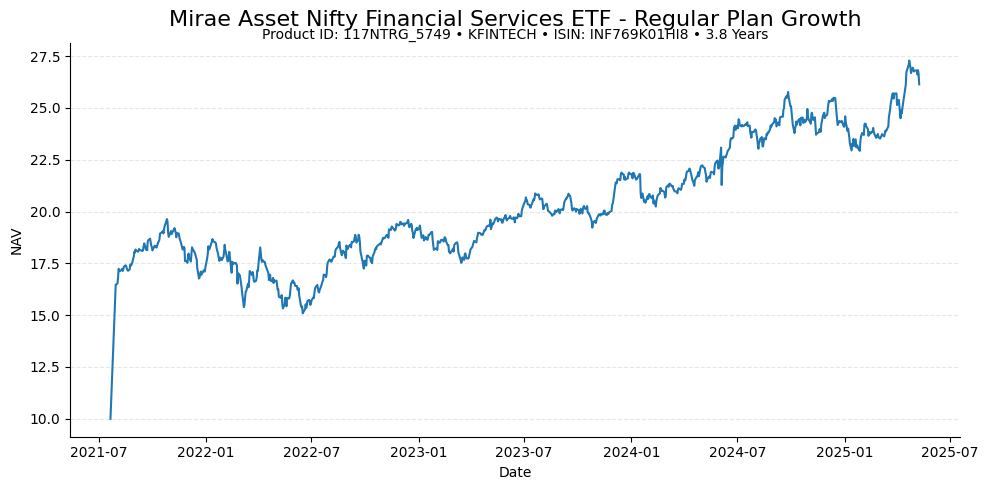

In [ ]:
# @title 117NTRG_5749 — NAV History

plot_nav("117NTRG_5749")

In [ ]:
# @title Top Performing Funds  — 6-Year Duration

six_year = df[df["duration_years"] == 6].sort_values(
    "total_return_pct",
    ascending=False
)

result = six_year[
    [
        "RTA",
        "product_id",
        "total_return_pct",
        "annualized_return_pct",
        "best_year_return_pct",
        "worst_year_return_pct",
        "max_drawdown_pct",
        "downside_volatility",
        "sortino_ratio"
    ]
].rename(columns={
    "total_return_pct": "Total Return (%)",
    "annualized_return_pct": "Annualized Return (%)",
    "best_year_return_pct": "Best Year Return (%)",
    "worst_year_return_pct": "Worst Year Return (%)",
    "max_drawdown_pct": "Max Drawdown (%)",
    "downside_volatility": "Downside Volatility",
    "sortino_ratio": "Sortino Ratio"
}).reset_index(drop=True)

result.index = result.index + 1

result

,RTA,product_id,Total Return (%),Annualized Return (%),Best Year Return (%),Worst Year Return (%),Max Drawdown (%),Downside Volatility,Sortino Ratio
1,KFINTECH,116SCDG_5459,361.60000,29.036022,71.334923,-15.843209,-32.367150,16.522656,1.333685
2,KFINTECH,118SCD1_6288,334.83000,27.757552,68.353207,-12.581170,-37.086251,16.352777,1.269359
3,KFINTECH,116SCRG_5461,314.90000,26.762435,68.502475,-16.300182,-32.510288,16.534597,1.195217
4,KFINTECH,120SCD1_7059,306.00000,26.305134,63.584637,-14.938194,-37.659236,16.785751,1.150091
5,CAMS,TSCFGZ,299.07200,25.943341,72.461785,-15.433289,-36.605109,15.502686,1.221939
...,...,...,...,...,...,...,...,...,...
649,CAMS,G336,0.00073,0.000122,0.008069,0.000000,-0.056657,0.139207,-50.283830
650,KFINTECH,178OND1_12359,0.00028,0.000047,0.000280,0.000000,-0.025387,0.013041,-536.756085
651,KFINTECH,178ONID_12364,0.00018,0.000030,0.000180,-0.000020,-0.011589,0.006527,-1072.390462
652,CAMS,FTI865,0.00008,0.000013,0.000080,0.000000,-0.058336,0.031123,-224.914589


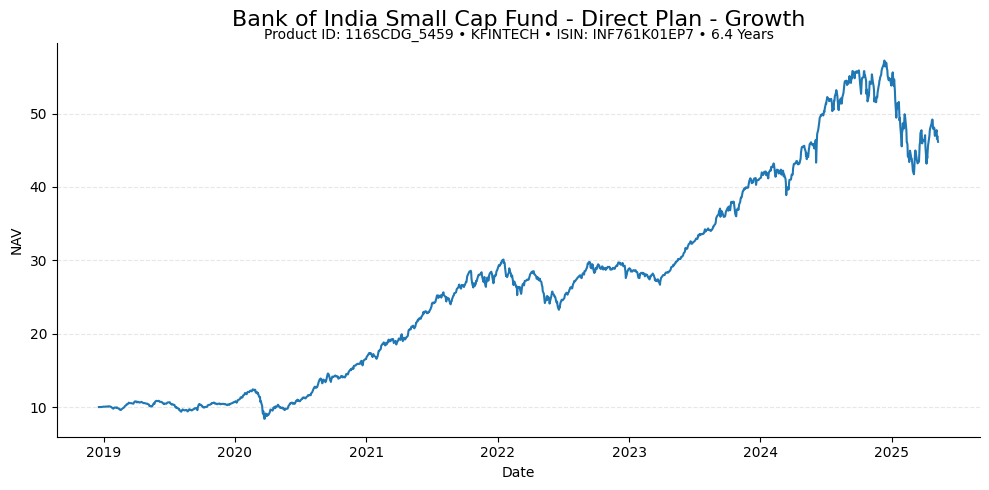

In [ ]:
# @title 116SCDG_5459 — NAV History

plot_nav("116SCDG_5459")

In [ ]:
# @title Top Performing Funds — 10-Year Duration

ten_year = df[df["duration_years"] == 10].sort_values(
    "total_return_pct",
    ascending=False
)

result = ten_year[
    [
        "RTA",
        "product_id",
        "total_return_pct",
        "annualized_return_pct",
        "best_year_return_pct",
        "worst_year_return_pct",
        "max_drawdown_pct",
        "downside_volatility",
        "sortino_ratio"
    ]
].rename(columns={
    "total_return_pct": "Total Return (%)",
    "annualized_return_pct": "Annualized Return (%)",
    "best_year_return_pct": "Best Year Return (%)",
    "worst_year_return_pct": "Worst Year Return (%)",
    "max_drawdown_pct": "Max Drawdown (%)",
    "downside_volatility": "Downside Volatility",
    "sortino_ratio": "Sortino Ratio"
}).reset_index(drop=True)

result.index = result.index + 1

result

,RTA,product_id,Total Return (%),Annualized Return (%),Best Year Return (%),Worst Year Return (%),Max Drawdown (%),Downside Volatility,Sortino Ratio
1,CAMS,OLEBDG,708.649000,23.246900,78.187191,-18.128407,-52.454848,15.254530,1.065054
2,CAMS,OLEBFG,629.235000,21.979472,76.316782,-18.425618,-53.549316,15.251970,0.982134
3,CAMS,P8573,452.800000,18.647011,47.966632,-11.017838,-44.820513,12.556781,0.927548
4,KFINTECH,127LTGD_7642,419.557000,17.913443,48.381853,-18.490123,-37.724914,15.143943,0.720647
5,CAMS,IFIGDG,401.304000,17.492492,37.467144,-5.137704,-36.570963,13.931421,0.753153
...,...,...,...,...,...,...,...,...,...
457,CAMS,D829,1.243000,0.123610,0.560052,-0.190268,-2.694055,1.339325,-5.134220
458,CAMS,D556,1.242000,0.123511,0.470261,-0.186334,-2.701457,1.295296,-5.308816
459,CAMS,D828,1.214000,0.120742,0.555065,-0.053324,-1.528308,0.576682,-11.929029
460,KFINTECH,105AAPD_1356,0.603963,0.060233,7.793741,-44.136164,-46.291236,19.348673,-0.358669


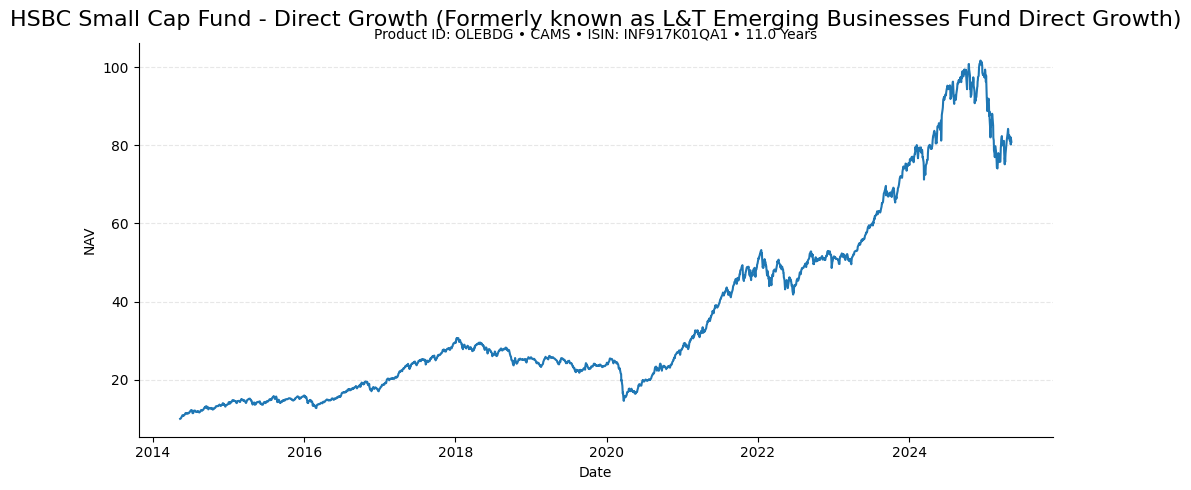

In [ ]:
# @title OLEBDG — NAV History

plot_nav("OLEBDG")

In [ ]:
# @title Top Performing Funds — 12-Year Duration

twelve_year = df[df["duration_years"] == 12].sort_values(
    "total_return_pct",
    ascending=False
)

result = twelve_year[
    [
        "RTA",
        "product_id",
        "total_return_pct",
        "annualized_return_pct",
        "best_year_return_pct",
        "worst_year_return_pct",
        "max_drawdown_pct",
        "downside_volatility",
        "sortino_ratio"
    ]
].rename(columns={
    "total_return_pct": "Total Return (%)",
    "annualized_return_pct": "Annualized Return (%)",
    "best_year_return_pct": "Best Year Return (%)",
    "worst_year_return_pct": "Worst Year Return (%)",
    "max_drawdown_pct": "Max Drawdown (%)",
    "downside_volatility": "Downside Volatility",
    "sortino_ratio": "Sortino Ratio"
}).reset_index(drop=True)

result.index = result.index + 1

result

,RTA,product_id,Total Return (%),Annualized Return (%),Best Year Return (%),Worst Year Return (%),Max Drawdown (%),Downside Volatility,Sortino Ratio
1,KFINTECH,RMFSCAG_14870,1445.336705,25.627657,97.569986,-15.728345,-48.583718,15.194608,1.225939
2,KFINTECH,RMFSCAB_14868,1445.336705,25.627657,97.569986,-15.728345,-48.583718,15.196383,1.225795
3,CAMS,LD346G,1310.859937,24.678143,112.551485,-18.685315,-40.260128,12.709885,1.390897
4,KFINTECH,118MSD1_6201,1063.650223,22.692648,84.975094,-14.593166,-39.205459,14.318405,1.095977
5,KFINTECH,117EBD1_5547,1002.746077,22.144231,85.504790,-4.814530,-36.866728,13.898997,1.089592
...,...,...,...,...,...,...,...,...,...
1493,CAMS,P8098,0.055698,0.004640,0.032620,-0.116594,-0.396306,0.853481,-8.196265
1494,CAMS,D799,0.049694,0.004140,0.041378,-0.086797,-0.423290,0.773602,-9.043227
1495,CAMS,UKLWRD,0.035783,0.002981,1.300484,-1.389255,-3.552169,0.986550,-7.092411
1496,KFINTECH,101LIDW_244,0.020446,0.001704,0.120409,-0.048707,-0.279835,0.726284,-9.635762


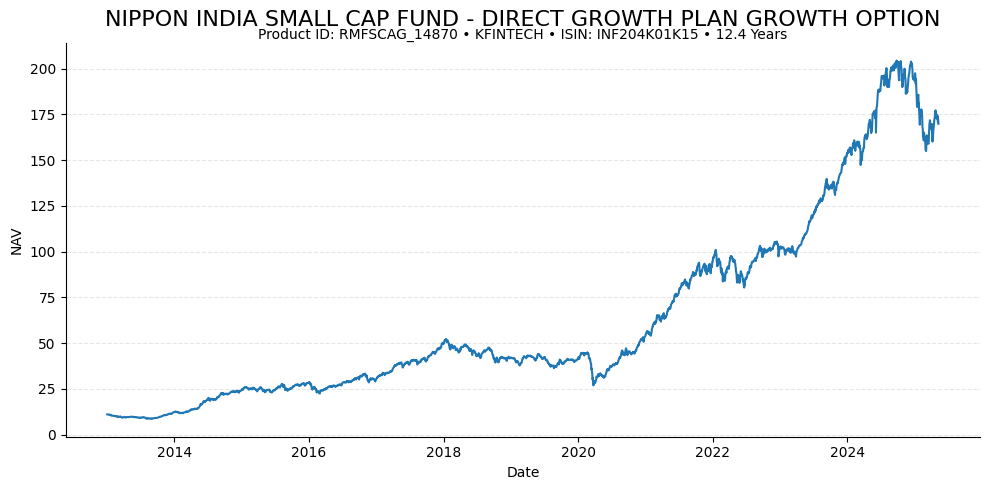

In [ ]:
# @title RMFSCAG_14870 — NAV History

plot_nav("RMFSCAG_14870")

In [ ]:
# @title Top Performing Funds — 14-Year Duration

fourteen_year = df[df["duration_years"] == 14].sort_values(
    "total_return_pct",
    ascending=False
)

result = fourteen_year[
    [
        "RTA",
        "product_id",
        "total_return_pct",
        "annualized_return_pct",
        "best_year_return_pct",
        "worst_year_return_pct",
        "max_drawdown_pct",
        "downside_volatility",
        "sortino_ratio"
    ]
].rename(columns={
    "total_return_pct": "Total Return (%)",
    "annualized_return_pct": "Annualized Return (%)",
    "best_year_return_pct": "Best Year Return (%)",
    "worst_year_return_pct": "Worst Year Return (%)",
    "max_drawdown_pct": "Max Drawdown (%)",
    "downside_volatility": "Downside Volatility",
    "sortino_ratio": "Sortino Ratio"
}).reset_index(drop=True)

result.index = result.index + 1

result

,RTA,product_id,Total Return (%),Annualized Return (%),Best Year Return (%),Worst Year Return (%),Max Drawdown (%),Downside Volatility,Sortino Ratio
1,KFINTECH,RMFSCGP_14873,1418.315000,21.445937,95.886591,-25.505146,-49.723910,14.357855,1.006135
2,KFINTECH,RMFSCBP_14871,1418.315000,21.445937,95.886591,-25.518727,-49.723910,14.357546,1.006156
3,KFINTECH,117EBRG_5550,1276.240000,20.596665,83.622109,-15.719329,-36.961254,13.201014,1.029971
4,KFINTECH,128MCGP_8154,928.100000,18.110427,75.796178,-11.400000,-29.443405,11.948251,0.929879
5,KFINTECH,117ICRG_5638,771.400000,16.723526,50.899466,-5.881082,-35.690582,11.491513,0.846148
...,...,...,...,...,...,...,...,...,...
246,KFINTECH,116LFDD_5369,0.255306,0.018215,0.260679,0.000000,-0.249426,0.058141,-120.082958
247,KFINTECH,120LFSD_6847,0.197295,0.014080,0.097786,0.000000,-0.308374,0.081019,-86.226167
248,CAMS,D407,0.132628,0.009468,10.094808,-12.599641,-24.667087,6.004078,-1.164297
249,KFINTECH,101FRDM_166,0.091618,0.006541,0.046784,-0.159589,-2.547746,2.738397,-2.553851


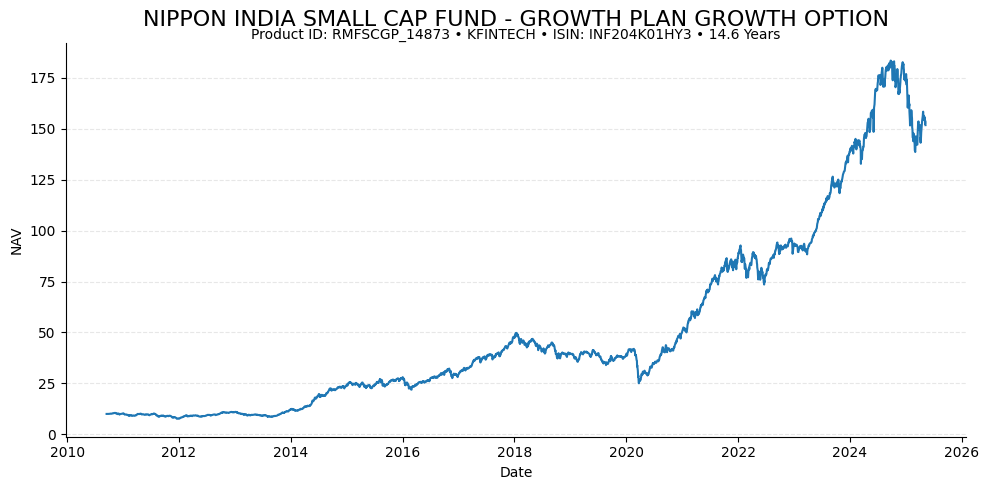

In [ ]:
# @title RMFSCGP_14873 — NAV History

plot_nav("RMFSCGP_14873")

In [ ]:
# @title Top Performing Funds — 25-Year Duration

twenty_five_year = df[df["duration_years"] == 25].sort_values(
    "total_return_pct",
    ascending=False
)

result = twenty_five_year[
    [
        "RTA",
        "product_id",
        "total_return_pct",
        "annualized_return_pct",
        "best_year_return_pct",
        "worst_year_return_pct",
        "max_drawdown_pct",
        "downside_volatility",
        "sortino_ratio"
    ]
].rename(columns={
    "total_return_pct": "Total Return (%)",
    "annualized_return_pct": "Annualized Return (%)",
    "best_year_return_pct": "Best Year Return (%)",
    "worst_year_return_pct": "Worst Year Return (%)",
    "max_drawdown_pct": "Max Drawdown (%)",
    "downside_volatility": "Downside Volatility",
    "sortino_ratio": "Sortino Ratio"
}).reset_index(drop=True)

result.index = result.index + 1

result

,RTA,product_id,Total Return (%),Annualized Return (%),Best Year Return (%),Worst Year Return (%),Max Drawdown (%),Downside Volatility,Sortino Ratio
1,CAMS,FTI036,16777.603574,22.770050,175.615595,-62.724444,-70.117850,16.502562,0.955612
2,CAMS,H02,12040.180529,21.162718,125.209607,-49.963935,-59.920567,16.259117,0.871063
3,CAMS,FTI037,10830.206872,20.654948,115.918654,-47.658448,-57.857143,15.762097,0.866315
4,CAMS,P01,8681.500000,19.603186,149.960784,-56.426023,-69.168803,17.578401,0.716970
5,CAMS,H62,4526.566063,16.576322,119.456722,-55.174633,-62.789289,14.962786,0.640009
...,...,...,...,...,...,...,...,...,...
74,CAMS,FTI039,15.881599,0.591337,11.752900,-7.421516,-26.105003,3.620672,-1.770020
75,CAMS,B403QD,15.762000,0.587182,11.398437,-14.925814,-18.796038,7.250558,-0.884459
76,CAMS,O43,11.691000,0.443243,19.207216,-15.777975,-22.374943,6.601326,-0.993248
77,CAMS,FTI042,11.596497,0.439842,5.641390,-0.066848,-0.550689,0.681158,-9.630897


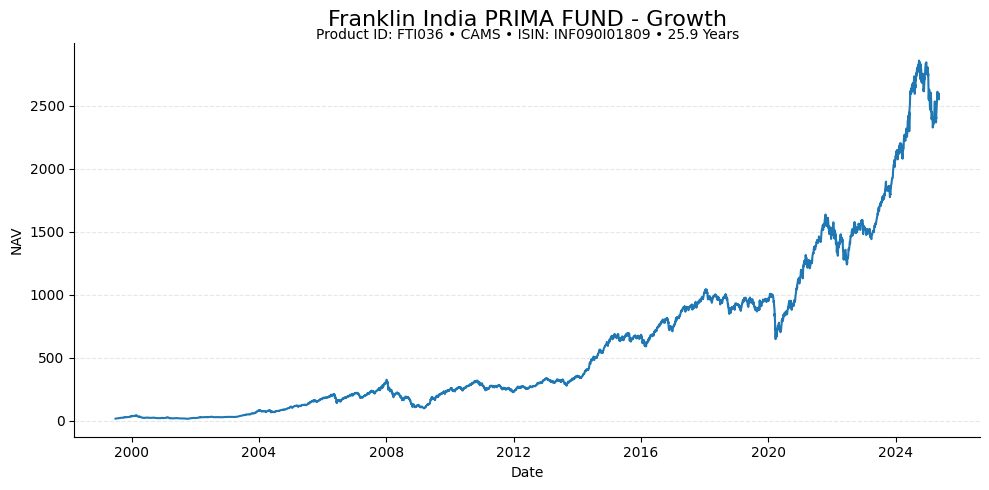

In [ ]:
# @title FTI036 — NAV History

plot_nav("FTI036")

## Overall Fund Performance — Sortino Ratio: Return Relative to Downside Risk

In [ ]:
# @title Fund Performance — Annualized Return ≥ 14% and Duration ≥ 3 Years

filtered = df[
    (df["annualized_return_pct"] >= 14) &
    (df["duration_years"] >= 3)
].sort_values(
    "sortino_ratio",
    ascending=False
)

result = filtered[
    [
        "RTA",
        "product_id",
        "duration_years",
        "total_return_pct",
        "annualized_return_pct",
        "best_year_return_pct",
        "worst_year_return_pct",
        "max_drawdown_pct",
        "downside_volatility",
        "sortino_ratio"
    ]
].rename(columns={
    "duration_years": "Duration (Years)",
    "total_return_pct": "Total Return (%)",
    "annualized_return_pct": "Annualized Return (%)",
    "best_year_return_pct": "Best Year Return (%)",
    "worst_year_return_pct": "Worst Year Return (%)",
    "max_drawdown_pct": "Max Drawdown (%)",
    "downside_volatility": "Downside Volatility",
    "sortino_ratio": "Sortino Ratio"
}).reset_index(drop=True)

result.index = result.index + 1

result

,RTA,product_id,Duration (Years),Total Return (%),Annualized Return (%),Best Year Return (%),Worst Year Return (%),Max Drawdown (%),Downside Volatility,Sortino Ratio
1,CAMS,LD619G,4,317.783000,42.967621,79.794598,-8.982911,-15.736416,9.445219,3.808024
2,CAMS,L619G,4,293.237000,40.819758,77.052230,-9.310692,-15.886653,9.455074,3.576890
3,CAMS,PPCHFGZ,3,50.531000,14.606341,13.813105,3.882544,-2.322675,2.253722,3.375013
4,CAMS,PPCHFG,3,48.763000,14.155886,13.481694,3.773901,-2.379825,2.254504,3.174040
5,CAMS,K271,3,98.097000,25.591226,34.257000,-0.285407,-18.094143,7.597389,2.447055
...,...,...,...,...,...,...,...,...,...,...
1437,KFINTECH,127BIGD_7558,5,97.305000,14.558579,18.699637,-3.053370,-46.852221,20.425853,0.370050
1438,CAMS,H32,25,3114.024566,14.889931,119.203354,-57.803468,-67.412217,21.629965,0.364769
1439,CAMS,L801,19,2154.249000,17.817723,83.961118,-53.026775,-60.233593,32.096983,0.337032
1440,KFINTECH,123EFDP_7275,19,1138.636364,14.162471,98.195329,-48.323699,-53.872633,22.174887,0.322999


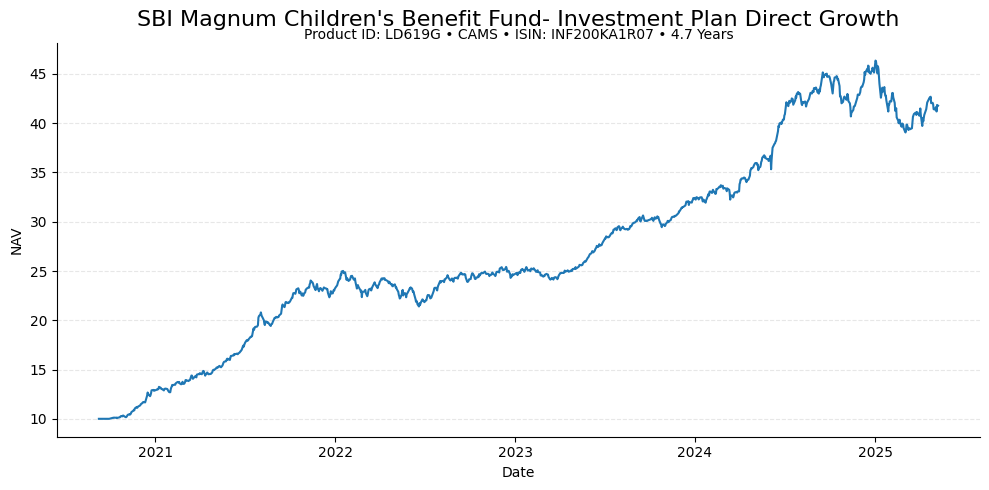

In [ ]:
# @title LD619G NAV History

plot_nav("LD619G")